<a href="https://colab.research.google.com/github/drishikaaneja/flyrank-ml-internship-starter/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q duckdb huggingface_hub

from google.colab import userdata
from huggingface_hub import list_repo_files

HF_TOKEN = userdata.get('HF_TOKEN1')
DATASET = "FlyRank/internship-warehouse"

files = list_repo_files(DATASET, repo_type="dataset", token=HF_TOKEN)
for f in files:
    print(f)

.gitattributes
README.md
dim_clients.parquet
dim_content.parquet
fact_content_daily_performance/month=2025-01/data_0.parquet
fact_content_daily_performance/month=2025-02/data_0.parquet
fact_content_daily_performance/month=2025-03/data_0.parquet
fact_content_daily_performance/month=2025-04/data_0.parquet
fact_content_daily_performance/month=2025-05/data_0.parquet
fact_content_daily_performance/month=2025-06/data_0.parquet
fact_content_daily_performance/month=2025-07/data_0.parquet
fact_content_daily_performance/month=2025-08/data_0.parquet
fact_content_daily_performance/month=2025-09/data_0.parquet
fact_content_daily_performance/month=2025-10/data_0.parquet
fact_content_daily_performance/month=2025-11/data_0.parquet
fact_content_daily_performance/month=2025-12/data_0.parquet
fact_content_daily_performance/month=2026-01/data_0.parquet
fact_content_daily_performance/month=2026-02/data_0.parquet
fact_content_daily_performance/month=2026-03/data_0.parquet
fact_content_daily_performance/mont

In [3]:
import duckdb
con = duckdb.connect()
con.execute(f"CREATE SECRET hf (TYPE huggingface, TOKEN '{HF_TOKEN}')")
BASE = f"hf://datasets/{DATASET}"

tables = ["dim_clients.parquet",
          "dim_content.parquet",
          "fact_content_daily_performance_sample.parquet",
          "fact_content_query_90d.parquet"]

for t in tables:
    print("=====", t, "=====")
    cols = con.sql(f"DESCRIBE SELECT * FROM '{BASE}/{t}'").df()
    print(cols[["column_name", "column_type"]].to_string(index=False))
    print()

===== dim_clients.parquet =====
        column_name column_type
     client_hash_id     VARCHAR
          is_active     BOOLEAN
     has_gsc_access     BOOLEAN
     has_ga4_access     BOOLEAN
     access_profile     VARCHAR
client_created_date        DATE
client_updated_date        DATE
     gsc_data_start        DATE
     ga4_data_start        DATE

===== dim_content.parquet =====
               column_name column_type
            client_hash_id     VARCHAR
           content_hash_id     VARCHAR
           keyword_hash_id     VARCHAR
               url_hash_id     VARCHAR
        keyword_char_count      BIGINT
       keyword_token_count      BIGINT
            url_char_count      BIGINT
      content_created_date        DATE
      content_updated_date        DATE
              content_type     VARCHAR
             search_volume      BIGINT
               competition      DOUBLE
         competition_level     VARCHAR
                       cpc      DOUBLE
               main_intent    

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Number of pages: 101917
            pages  typical_ctr
pos_bucket                    
0.0             9     0.000974
1.0           210     0.002067
2.0          1316     0.002756
3.0          2389     0.004484
4.0          4125     0.004895
5.0          6406     0.004644
6.0          7779     0.003953
7.0          8385     0.003384
8.0          7526     0.002931
9.0          6201     0.002849
10.0         4760     0.002952
11.0         3930     0.003203
12.0         3369     0.003268
13.0         2944     0.003378
14.0         2681     0.003215
15.0         2306     0.003185
16.0         2122     0.002890
17.0         1950     0.002825
18.0         1798     0.002892
19.0         1721     0.003300
20.0        29990     0.000000


<Axes: title={'center': 'Typical click rate by Google position'}, xlabel='pos_bucket'>

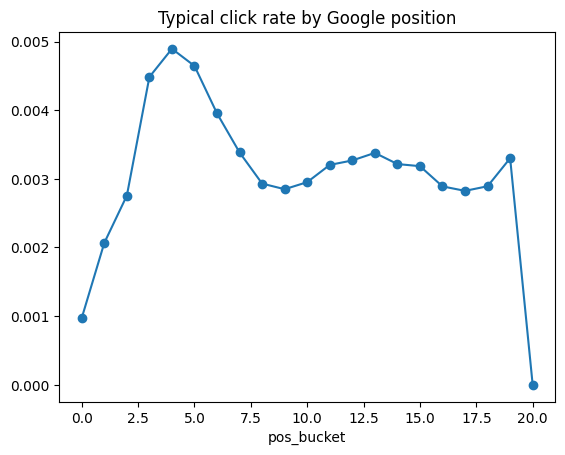

In [4]:
S = f"{BASE}/fact_content_daily_performance_sample.parquet"

pages = con.sql(f"""
    SELECT content_hash_id,
           SUM(gsc_impressions) AS impressions,
           SUM(gsc_clicks)      AS clicks,
           SUM(gsc_avg_position * gsc_impressions) / NULLIF(SUM(gsc_impressions), 0) AS position
    FROM '{S}'
    WHERE gsc_data_available
    GROUP BY content_hash_id
    HAVING SUM(gsc_impressions) >= 100
""").df()

pages["ctr"] = pages["clicks"] / pages["impressions"]
pages["pos_bucket"] = pages["position"].clip(upper=20).round()

print("Number of pages:", len(pages))
curve = pages.groupby("pos_bucket").agg(pages=("ctr", "size"), typical_ctr=("ctr", "median"))
print(curve)
curve["typical_ctr"].plot(marker="o", title="Typical click rate by Google position")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   overall_ctr  position_way1  position_way2
0     0.005593      10.067313      10.067313


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

    pos_bucket    rows       ctr
0          0.0  113779  0.001430
1          1.0   93142  0.006487
2          2.0  153390  0.004791
3          3.0   86534  0.004098
4          4.0  101527  0.003241
5          5.0  123369  0.002643
6          6.0  146894  0.002159
7          7.0  166580  0.001842
8          8.0  173341  0.001433
9          9.0  157072  0.001192
10        10.0  114605  0.000952
11        11.0   65666  0.001222
12        12.0   41221  0.001562
13        13.0   31687  0.001658
14        14.0   27483  0.001562
15        15.0   24644  0.001624
16        16.0   22651  0.001317
17        17.0   21101  0.001414
18        18.0   19380  0.001310
19        19.0   17870  0.001241
20        20.0  712312  0.000448


<Axes: title={'center': 'Click rate by position (per search)'}, xlabel='pos_bucket'>

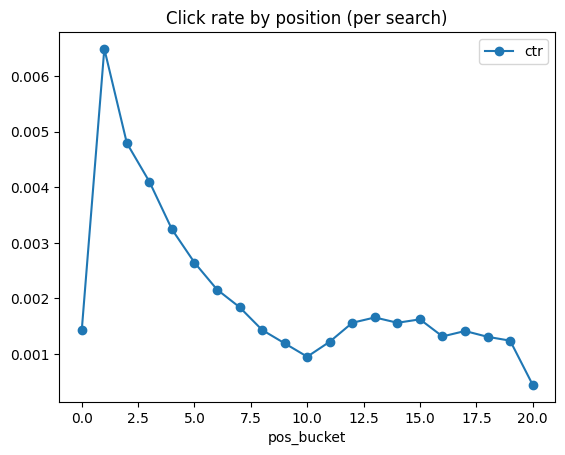

In [5]:
# Check 1: is the position number calculated the way we think?
check = con.sql(f"""
    SELECT SUM(gsc_clicks) * 1.0 / SUM(gsc_impressions)                     AS overall_ctr,
           SUM(gsc_avg_position * gsc_impressions) / SUM(gsc_impressions)   AS position_way1,
           SUM(gsc_sum_position) * 1.0 / SUM(gsc_impressions)               AS position_way2
    FROM '{S}'
    WHERE gsc_data_available
""").df()
print(check)

# Check 2: the same chart, but per search instead of per page
Q = f"{BASE}/fact_content_query_90d.parquet"
qcurve = con.sql(f"""
    SELECT LEAST(ROUND(avg_position_90d), 20) AS pos_bucket,
           COUNT(*)                            AS rows,
           SUM(clicks_90d) * 1.0 / SUM(impressions_90d) AS ctr
    FROM '{Q}'
    WHERE impressions_90d > 0
    GROUP BY 1
    ORDER BY 1
""").df()
print(qcurve)
qcurve.plot(x="pos_bucket", y="ctr", marker="o", title="Click rate by position (per search)")

In [6]:
# 1. Load search-level rows, removing invalid positions
qp = con.sql(f"""
    SELECT content_hash_id, query_hash_id, impressions_90d, clicks_90d, avg_position_90d,
           LEAST(ROUND(avg_position_90d), 20) AS pos_bucket
    FROM '{Q}'
    WHERE impressions_90d > 0 AND avg_position_90d >= 1
""").df()
print("Search rows kept:", len(qp))

# 2. Normal click rate for each position
norm = qp.groupby("pos_bucket")[["clicks_90d", "impressions_90d"]].sum()
norm["expected_ctr"] = norm["clicks_90d"] / norm["impressions_90d"]
qp = qp.merge(norm[["expected_ctr"]], on="pos_bucket")
qp["expected_clicks"] = qp["impressions_90d"] * qp["expected_ctr"]

# 3. Add it all up per page
page = qp.groupby("content_hash_id").agg(
    impressions=("impressions_90d", "sum"),
    clicks=("clicks_90d", "sum"),
    expected_clicks=("expected_clicks", "sum"),
    searches=("query_hash_id", "count"),
).reset_index()

page = page[page["impressions"] >= 500]          # only pages seen enough times
page["missing_clicks"] = page["expected_clicks"] - page["clicks"]

print("Pages analysed:", len(page))
print(page.sort_values("missing_clicks", ascending=False).head(10))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Search rows kept: 2274658
Pages analysed: 39020
                 content_hash_id  impressions  clicks  expected_clicks  \
75957   content_943dc881428182b8       606831     344      2786.259187   
106845  content_d0acf7062bc6b257       297755      33      1416.373035   
10772   content_15168cd1c94e3529       311895     178      1157.702910   
59479   content_7471467133493ce6       217524      30       887.039858   
97266   content_bddfdd871aa09fbe       156932       9       747.387959   
38833   content_4c15fe8dc370f3cd       266229     459      1148.584312   
72738   content_8e1334d6356668e3       158016       0       638.266718   
26432   content_33d31496fca9665e       273740      16       596.888084   
99361   content_c1f764a2f362d1c3       352256      54       623.316161   
88546   content_acbcc847f8996314       232177     279       804.545004   

        searches  missing_clicks  
75957        190     2442.259187  
106845        68     1383.373035  
10772         86      979.702910

In [7]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy.stats import spearmanr

# 1. Load search rows + page details
data = con.sql(f"""
    SELECT q.client_hash_id, q.content_hash_id,
           q.impressions_90d AS imp, q.clicks_90d AS clicks,
           q.avg_position_90d AS position, q.query_token_count, q.query_char_count,
           c.word_count, c.content_type, c.main_intent, c.competition, c.search_volume
    FROM '{Q}' q
    LEFT JOIN '{BASE}/dim_content.parquet' c USING (client_hash_id, content_hash_id)
    WHERE q.impressions_90d > 0 AND q.avg_position_90d >= 1
""").df()
print("Rows:", len(data), "(should be 2274658 - if bigger, tell me)")

data["pos_bucket"] = data["position"].clip(upper=20).round()
for col in ["content_type", "main_intent"]:
    data[col] = data[col].astype("category")

# 2. Hide 25% of companies for testing
split = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
tr, te = next(split.split(data, groups=data["client_hash_id"]))
train, test = data.iloc[tr].copy(), data.iloc[te].copy()
print("Train companies:", train.client_hash_id.nunique(), "| Test companies:", test.client_hash_id.nunique())

# 3. Baseline: normal click rate by rank (learned from train only)
norm = train.groupby("pos_bucket")[["clicks", "imp"]].sum()
norm["base_ctr"] = norm["clicks"] / norm["imp"]
test = test.merge(norm[["base_ctr"]], on="pos_bucket", how="left")
test["base_ctr"] = test["base_ctr"].fillna(0)

# 4. Smarter model
features = ["position", "query_token_count", "query_char_count", "word_count",
            "content_type", "main_intent", "competition", "search_volume"]
model = HistGradientBoostingRegressor(categorical_features="from_dtype", max_iter=200, random_state=42)
model.fit(train[features], train["clicks"] / train["imp"], sample_weight=train["imp"])
test["model_ctr"] = model.predict(test[features]).clip(0, 1)

# 5. Compare on pages from unseen companies
test["base_clicks"] = test["imp"] * test["base_ctr"]
test["model_clicks"] = test["imp"] * test["model_ctr"]
pg = test.groupby("content_hash_id")[["imp", "clicks", "base_clicks", "model_clicks"]].sum()
pg = pg[pg["imp"] >= 500]

print("\nTest pages:", len(pg))
for name in ["base_clicks", "model_clicks"]:
    err = (pg[name] - pg["clicks"]).abs().mean()
    rank = spearmanr(pg[name], pg["clicks"]).correlation
    print(f"{name:13s} -> average error: {err:.2f} clicks | ranking match: {rank:.3f}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Rows: 2274658 (should be 2274658 - if bigger, tell me)
Train companies: 39 | Test companies: 13

Test pages: 4217
base_clicks   -> average error: 6.34 clicks | ranking match: 0.735
model_clicks  -> average error: 6.23 clicks | ranking match: 0.736


In [9]:
from sklearn.model_selection import GroupKFold
import pandas as pd

def run_fold(train, test):
    norm = train.groupby("pos_bucket")[["clicks", "imp"]].sum()
    norm["base_ctr"] = norm["clicks"] / norm["imp"]
    test = test.merge(norm[["base_ctr"]], on="pos_bucket", how="left")
    test["base_ctr"] = test["base_ctr"].fillna(0)

    m = HistGradientBoostingRegressor(categorical_features="from_dtype", max_iter=200, random_state=42)
    m.fit(train[features], train["clicks"] / train["imp"], sample_weight=train["imp"])
    test["model_ctr"] = m.predict(test[features]).clip(0, 1)

    test["base_clicks"] = test["imp"] * test["base_ctr"]
    test["model_clicks"] = test["imp"] * test["model_ctr"]
    pg = test.groupby("content_hash_id")[["imp", "clicks", "base_clicks", "model_clicks"]].sum()
    pg = pg[pg["imp"] >= 500]

    out = {"test_pages": len(pg)}
    for n in ["base", "model"]:
        out[f"{n}_error"] = (pg[f"{n}_clicks"] - pg["clicks"]).abs().mean()
        out[f"{n}_rank"] = spearmanr(pg[f"{n}_clicks"], pg["clicks"]).correlation
    return out

results = []
gkf = GroupKFold(n_splits=5)
for i, (tr, te) in enumerate(gkf.split(data, groups=data["client_hash_id"])):
    r = run_fold(data.iloc[tr].copy(), data.iloc[te].copy())
    r["fold"] = i + 1
    results.append(r)
    print("Round", i + 1, "done")

res = pd.DataFrame(results).set_index("fold").round(3)
print(res)
print("\nAverage of 5 rounds:")
print(res.mean().round(3))
print("\nModel had lower error in", (res["model_error"] < res["base_error"]).sum(), "of 5 rounds")

Round 1 done
Round 2 done
Round 3 done
Round 4 done
Round 5 done
      test_pages  base_error  base_rank  model_error  model_rank
fold                                                            
1          10552       8.212      0.812        7.436       0.813
2           6932       7.272      0.560        8.959       0.569
3           7286       6.947      0.693        6.483       0.712
4           6695       9.904      0.673        9.611       0.688
5           7555       7.970      0.752        8.116       0.764

Average of 5 rounds:
test_pages     7804.000
base_error        8.061
base_rank         0.698
model_error       8.121
model_rank        0.709
dtype: float64

Model had lower error in 3 of 5 rounds


In [10]:
import numpy as np

# 1. Score every row with a model that never saw its company
data["oof_ctr"] = np.nan
for i, (tr, te) in enumerate(gkf.split(data, groups=data["client_hash_id"])):
    m = HistGradientBoostingRegressor(categorical_features="from_dtype", max_iter=200, random_state=42)
    train = data.iloc[tr]
    m.fit(train[features], train["clicks"] / train["imp"], sample_weight=train["imp"])
    data.loc[data.index[te], "oof_ctr"] = m.predict(data.iloc[te][features]).clip(0, 1)
    print("Round", i + 1, "scored")

# 2. Add up per page
data["exp_clicks"] = data["imp"] * data["oof_ctr"]
data["pos_x_imp"] = data["position"] * data["imp"]
pg = data.groupby("content_hash_id").agg(
    impressions=("imp", "sum"),
    clicks=("clicks", "sum"),
    expected_clicks=("exp_clicks", "sum"),
    pos_x_imp=("pos_x_imp", "sum"),
    searches=("imp", "size"),
).reset_index()
pg["position"] = pg["pos_x_imp"] / pg["impressions"]
pg = pg[pg["impressions"] >= 500].drop(columns="pos_x_imp")
pg["missing_clicks"] = pg["expected_clicks"] - pg["clicks"]
pg["click_ratio"] = pg["clicks"] / pg["expected_clicks"]

# 3. Reason codes
def reason(r):
    if r.clicks == 0 and r.impressions >= 5000:
        return "ZERO_CLICKS"
    if r.click_ratio >= 1:
        return "OK_PROTECT"
    if r.position <= 3:
        return "TOP3_LOW_CTR"
    if r.position <= 10:
        return "PAGE1_LOW_CTR"
    return "PAGE2_LOW_CTR"

pg["reason"] = pg.apply(reason, axis=1)

# 4. Results
print("\nPages per reason code:")
print(pg["reason"].value_counts())

ranked = pg[pg["reason"] != "OK_PROTECT"].sort_values("missing_clicks", ascending=False)
print("\nTop 15 pages to fix first:")
print(ranked[["content_hash_id", "impressions", "clicks", "expected_clicks",
              "position", "missing_clicks", "reason"]].head(15).round(1).to_string(index=False))

Round 1 scored
Round 2 scored
Round 3 scored
Round 4 scored
Round 5 scored

Pages per reason code:
reason
OK_PROTECT       14199
PAGE2_LOW_CTR    13080
PAGE1_LOW_CTR    10902
TOP3_LOW_CTR       454
ZERO_CLICKS        385
Name: count, dtype: int64

Top 15 pages to fix first:
         content_hash_id  impressions  clicks  expected_clicks  position  missing_clicks        reason
content_15168cd1c94e3529       311895     178           4476.2       3.5          4298.2 PAGE1_LOW_CTR
content_943dc881428182b8       606831     344           4119.6       2.0          3775.6  TOP3_LOW_CTR
content_d0acf7062bc6b257       297755      33           1243.6       2.1          1210.6  TOP3_LOW_CTR
content_4c15fe8dc370f3cd       266229     459           1633.7       3.0          1174.7 PAGE1_LOW_CTR
content_c1f764a2f362d1c3       352256      54            961.3       7.3           907.3 PAGE1_LOW_CTR
content_7471467133493ce6       217524      30            856.0       2.8           826.0  TOP3_LOW_CTR
cont

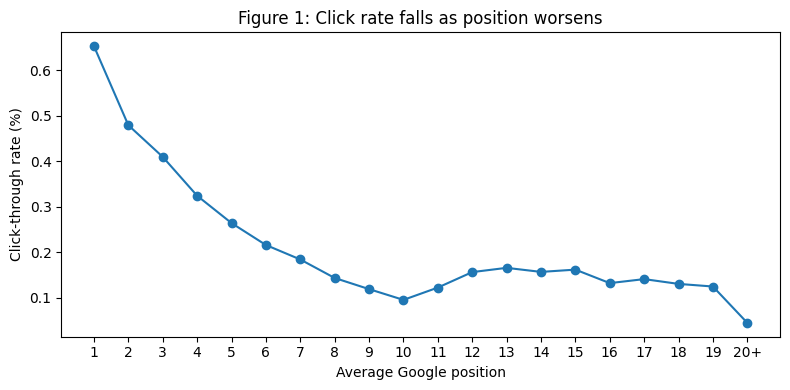

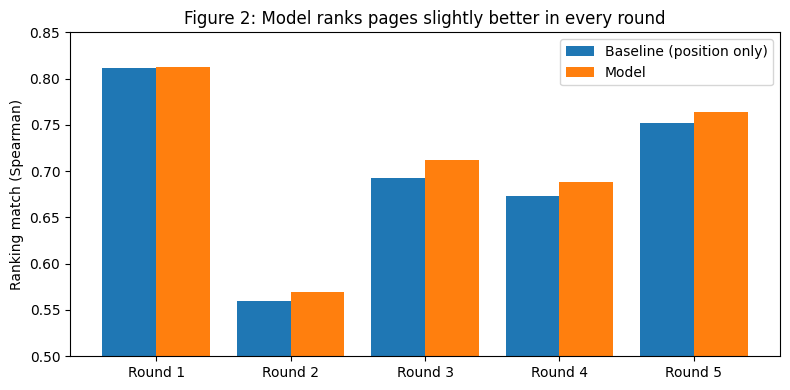

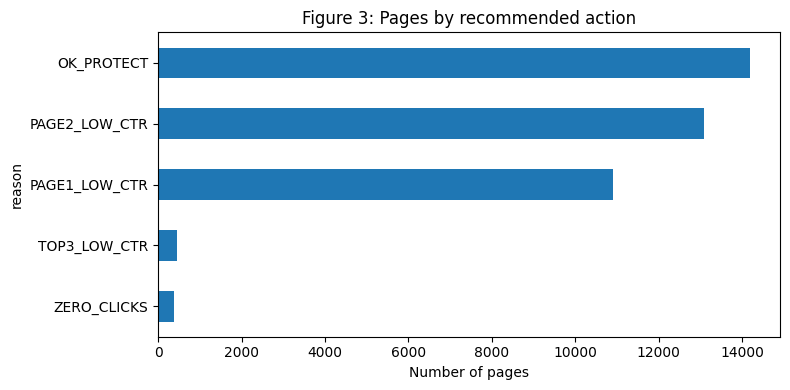

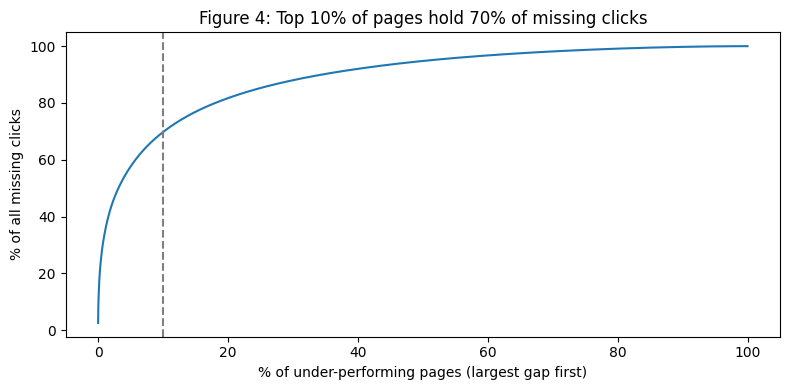

Top 10% of under-performing pages hold 69.7% of all missing clicks


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import matplotlib.pyplot as plt
from google.colab import files

# Figure 1: click rate by position
curve = data.groupby("pos_bucket")[["clicks", "imp"]].sum()
curve["ctr"] = curve["clicks"] / curve["imp"] * 100
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve.index, curve["ctr"], marker="o")
ax.set_xticks(range(1, 21))
ax.set_xticklabels([str(i) for i in range(1, 20)] + ["20+"])
ax.set_xlabel("Average Google position")
ax.set_ylabel("Click-through rate (%)")
ax.set_title("Figure 1: Click rate falls as position worsens")
plt.tight_layout(); plt.savefig("fig1_ctr_by_position.png", dpi=150); plt.show()

# Figure 2: baseline vs model, ranking match per round
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(res))
ax.bar(x - 0.2, res["base_rank"], 0.4, label="Baseline (position only)")
ax.bar(x + 0.2, res["model_rank"], 0.4, label="Model")
ax.set_xticks(x); ax.set_xticklabels([f"Round {i}" for i in res.index])
ax.set_ylim(0.5, 0.85)
ax.set_ylabel("Ranking match (Spearman)")
ax.set_title("Figure 2: Model ranks pages slightly better in every round")
ax.legend()
plt.tight_layout(); plt.savefig("fig2_model_vs_baseline.png", dpi=150); plt.show()

# Figure 3: pages per reason code
counts = pg["reason"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
counts.plot(kind="barh", ax=ax)
ax.invert_yaxis()
ax.set_xlabel("Number of pages")
ax.set_title("Figure 3: Pages by recommended action")
plt.tight_layout(); plt.savefig("fig3_reason_codes.png", dpi=150); plt.show()

# Figure 4: how concentrated are the missing clicks?
mc = ranked["missing_clicks"].values
cum = np.cumsum(mc) / mc.sum() * 100
pct_pages = np.arange(1, len(mc) + 1) / len(mc) * 100
top10 = cum[int(len(mc) * 0.10) - 1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pct_pages, cum)
ax.axvline(10, linestyle="--", color="grey")
ax.set_xlabel("% of under-performing pages (largest gap first)")
ax.set_ylabel("% of all missing clicks")
ax.set_title(f"Figure 4: Top 10% of pages hold {top10:.0f}% of missing clicks")
plt.tight_layout(); plt.savefig("fig4_concentration.png", dpi=150); plt.show()

print(f"Top 10% of under-performing pages hold {top10:.1f}% of all missing clicks")

for f in ["fig1_ctr_by_position.png", "fig2_model_vs_baseline.png",
          "fig3_reason_codes.png", "fig4_concentration.png"]:
    files.download(f)

In [12]:
print(con.sql(f"SELECT MIN(window_start) AS start, MAX(window_end) AS end FROM '{Q}'").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

       start        end
0 2026-04-02 2026-06-30
